# Digital Image Processing – Assignment 3
**Name:** Abisha
**ID:** 232031056

## What is Image Enhancement?

Image enhancement refers to the process of improving the visual quality or interpretability of an image for a specific application, such as medical imaging, satellite imagery, or surveillance.

Enhancement techniques operate in two domains: **spatial domain** (direct pixel manipulation) and **frequency domain** (modifying the Fourier transform of the image). Common spatial-domain methods include contrast stretching, histogram equalisation, and sharpening filters.

The goal is not to produce a "perfect" image, but rather to make features of interest more distinguishable. For example, histogram equalisation spreads pixel intensities across the full range, improving contrast in low-contrast images, while noise reduction filters suppress unwanted artifacts.

Image loaded. Shape: (512, 512)
Low-contrast image created. Range: 80 - 182


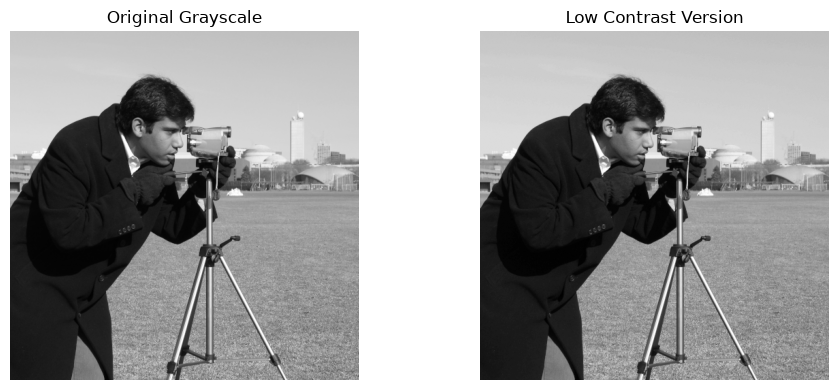

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
from PIL import Image
import urllib.request
import os

# Helper: load image from GitHub raw URL with fallback to skimage
def load_image(filename, gray=False):
    url = f"https://raw.githubusercontent.com/id-232031056/dip/main/images/{filename}"
    try:
        resp = urllib.request.urlopen(url, timeout=10)
        arr = np.asarray(bytearray(resp.read()), dtype=np.uint8)
        flag = cv2.IMREAD_GRAYSCALE if gray else cv2.IMREAD_COLOR
        img = cv2.imdecode(arr, flag)
        if img is not None:
            if not gray:
                img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            return img
    except Exception:
        pass
    # Fallback to skimage
    from skimage import data
    if gray:
        return data.camera()  # classic grayscale test image
    return data.astronaut()

REPO_IMG_BASE = "https://raw.githubusercontent.com/id-232031056/dip/main/images"

# Load a low-contrast grayscale image for histogram equalisation demo
# We'll use skimage camera and artificially reduce contrast for demo
from skimage import data as skdata
img_gray = load_image("test_gray.png", gray=True)
# Also create a low-contrast version
low_contrast = np.clip(img_gray * 0.4 + 80, 0, 255).astype(np.uint8)

print("Image loaded. Shape:", img_gray.shape)
print("Low-contrast image created. Range:", low_contrast.min(), "-", low_contrast.max())
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1); plt.imshow(img_gray, cmap='gray'); plt.title("Original Grayscale"); plt.axis('off')
plt.subplot(1, 2, 2); plt.imshow(low_contrast, cmap='gray'); plt.title("Low Contrast Version"); plt.axis('off')
plt.tight_layout(); plt.show()

## Task 3.1 – Histogram Generation

A histogram of a digital image shows the frequency of each intensity level (0–255) in the image.
It is computed by counting the number of pixels at each intensity value.
The histogram provides insight into the distribution of pixel intensities and is fundamental for many enhancement techniques.

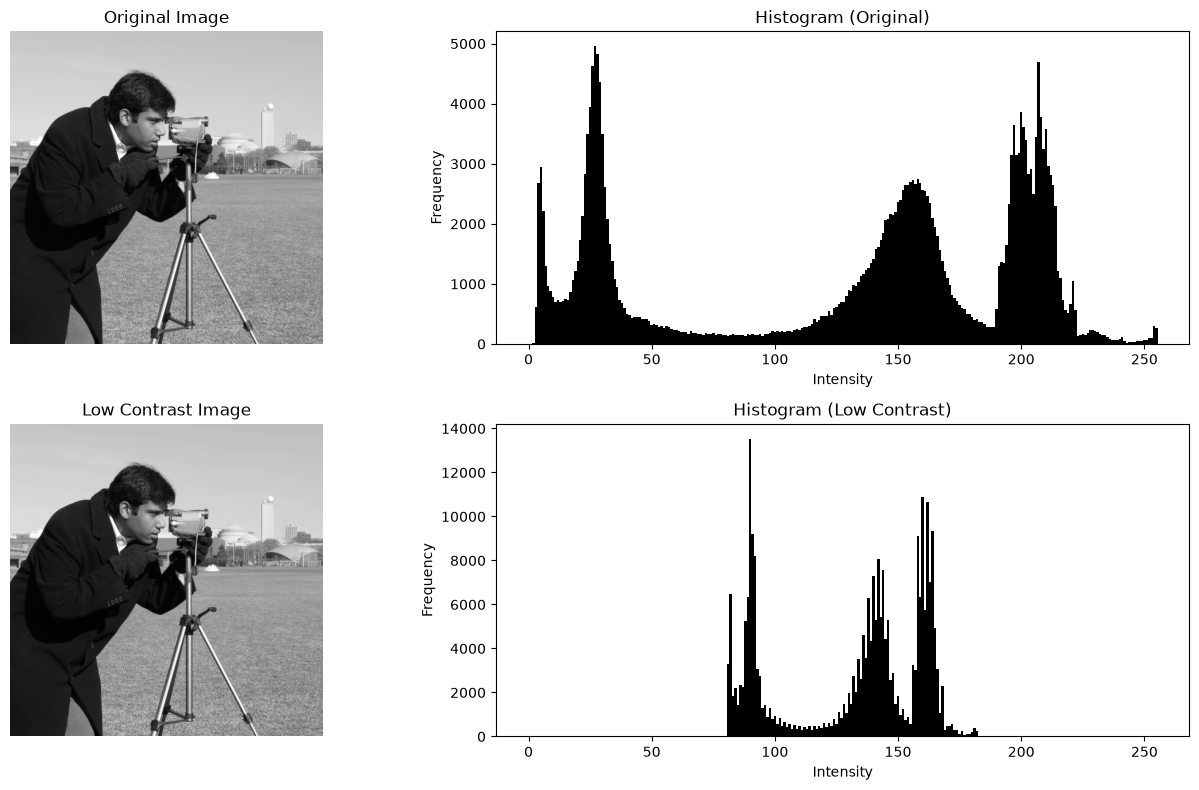

Total pixels (original): 262144 == image size: 262144


In [2]:
def compute_histogram(image, bins=256):
    """Manually compute histogram of a grayscale image."""
    hist = np.zeros(bins, dtype=np.int64)
    for val in image.ravel():
        hist[val] += 1
    return hist

# Compute histograms for both images
hist_original = compute_histogram(img_gray)
hist_low = compute_histogram(low_contrast)

# Plot histograms
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
axes[0, 0].imshow(img_gray, cmap='gray'); axes[0, 0].set_title("Original Image"); axes[0, 0].axis('off')
axes[0, 1].bar(range(256), hist_original, color='black', width=1)
axes[0, 1].set_title("Histogram (Original)"); axes[0, 1].set_xlabel("Intensity"); axes[0, 1].set_ylabel("Frequency")

axes[1, 0].imshow(low_contrast, cmap='gray'); axes[1, 0].set_title("Low Contrast Image"); axes[1, 0].axis('off')
axes[1, 1].bar(range(256), hist_low, color='black', width=1)
axes[1, 1].set_title("Histogram (Low Contrast)"); axes[1, 1].set_xlabel("Intensity"); axes[1, 1].set_ylabel("Frequency")

plt.tight_layout(); plt.show()
print("Total pixels (original):", hist_original.sum(), "== image size:", img_gray.size)

## Task 3.2 – Image PDF / Normalised Histogram

The Probability Density Function (PDF) of an image is the normalised histogram: each bin value
is divided by the total number of pixels. This gives the probability of each intensity level.
The sum of all PDF values equals 1.

Sum of PDF (original): 1.0000000000
Sum of PDF (low contrast): 1.0000000000


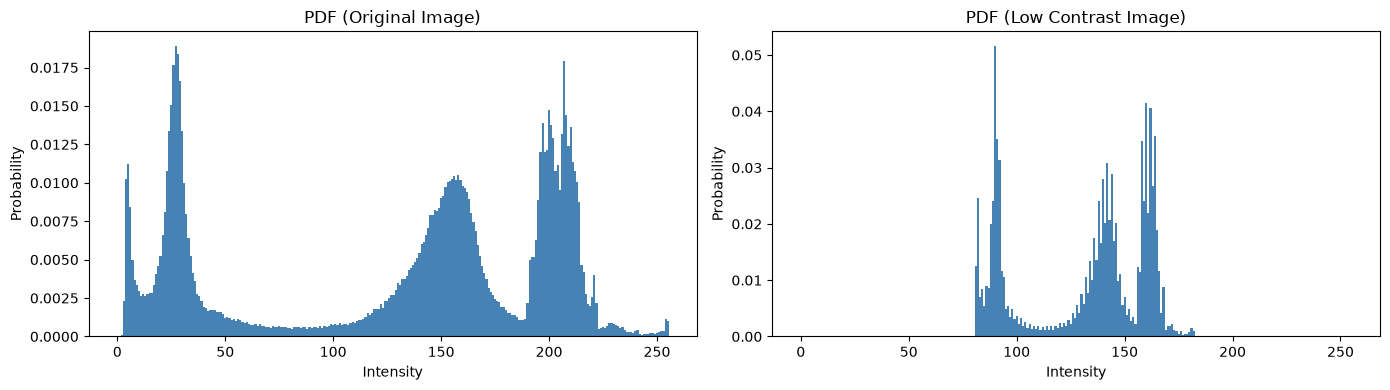

In [3]:
def compute_pdf(histogram):
    """Compute normalised histogram (PDF) from a histogram."""
    total_pixels = histogram.sum()
    pdf = histogram.astype(np.float64) / total_pixels
    return pdf

pdf_original = compute_pdf(hist_original)
pdf_low = compute_pdf(hist_low)

# Verify sum = 1
print(f"Sum of PDF (original): {pdf_original.sum():.10f}")
print(f"Sum of PDF (low contrast): {pdf_low.sum():.10f}")

# Plot PDFs
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].bar(range(256), pdf_original, color='steelblue', width=1)
axes[0].set_title("PDF (Original Image)"); axes[0].set_xlabel("Intensity"); axes[0].set_ylabel("Probability")

axes[1].bar(range(256), pdf_low, color='steelblue', width=1)
axes[1].set_title("PDF (Low Contrast Image)"); axes[1].set_xlabel("Intensity"); axes[1].set_ylabel("Probability")

plt.tight_layout(); plt.show()

## Task 3.3 – CDF Generation

The Cumulative Distribution Function (CDF) is the cumulative sum of the PDF.
CDF(k) = sum of PDF(i) for i = 0 to k. The CDF increases monotonically from 0 to 1
and is used as the intensity mapping function in histogram equalisation.

CDF final value (original): 1.0000000000
CDF final value (low contrast): 1.0000000000


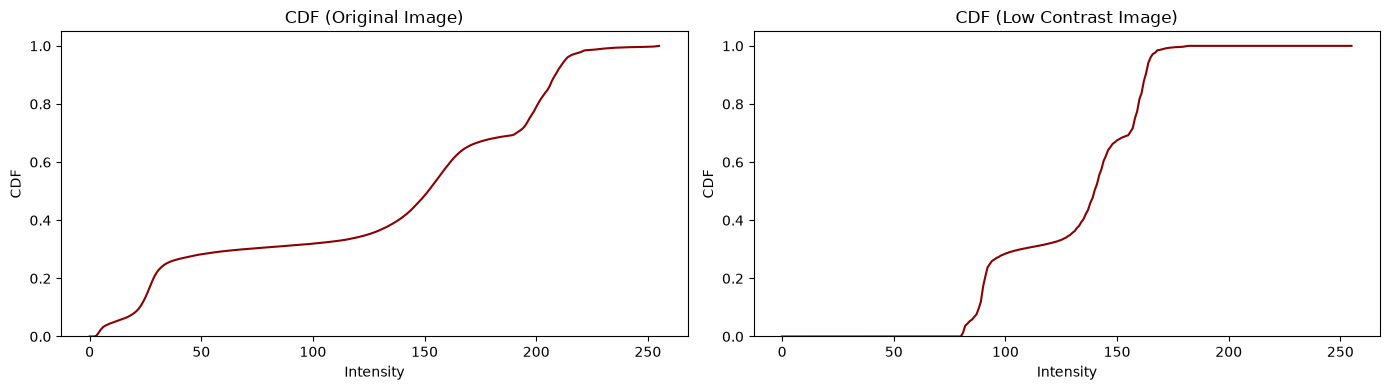

In [4]:
def compute_cdf(pdf):
    """Compute CDF from a PDF using cumulative sum."""
    return np.cumsum(pdf)

cdf_original = compute_cdf(pdf_original)
cdf_low = compute_cdf(pdf_low)

# Verify CDF ends at 1
print(f"CDF final value (original): {cdf_original[-1]:.10f}")
print(f"CDF final value (low contrast): {cdf_low[-1]:.10f}")

# Plot CDFs
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(range(256), cdf_original, color='darkred', linewidth=1.5)
axes[0].set_title("CDF (Original Image)"); axes[0].set_xlabel("Intensity"); axes[0].set_ylabel("CDF")
axes[0].set_ylim([0, 1.05])

axes[1].plot(range(256), cdf_low, color='darkred', linewidth=1.5)
axes[1].set_title("CDF (Low Contrast Image)"); axes[1].set_xlabel("Intensity"); axes[1].set_ylabel("CDF")
axes[1].set_ylim([0, 1.05])

plt.tight_layout(); plt.show()

## Task 3.4 – Histogram Equalisation

Histogram equalisation uses the CDF as a mapping function to redistribute pixel intensities
across the full range [0, 255]. The mapping is: s = round(CDF(r) × (L−1)), where L = 256.
This produces an image with a more uniform histogram, thereby improving contrast.

Max difference (manual vs cv2.equalizeHist): 1
Mean difference: 0.0246


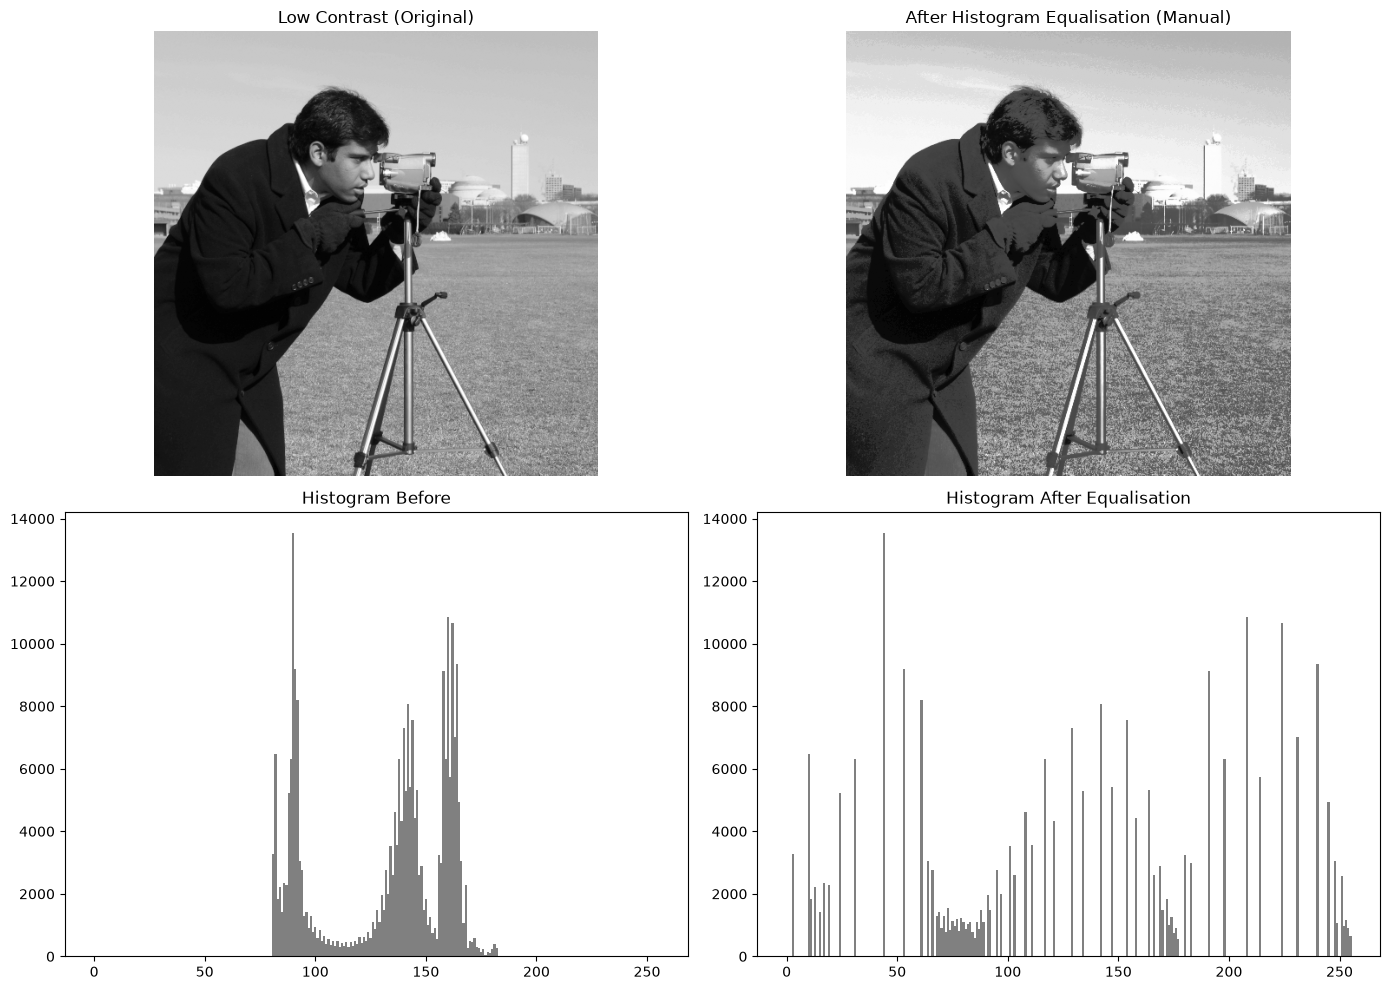

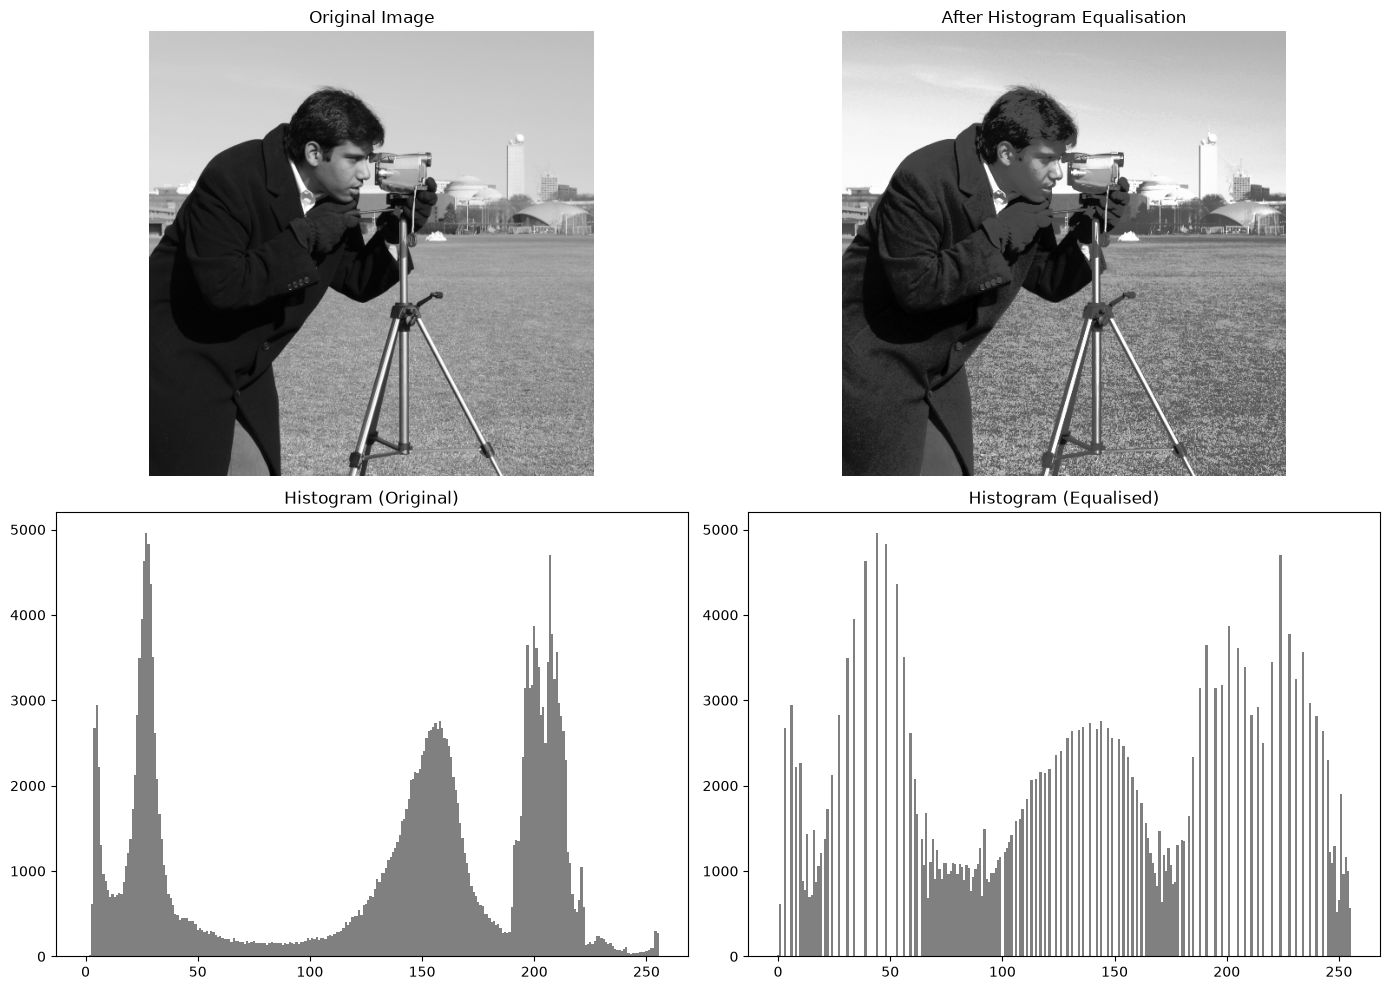

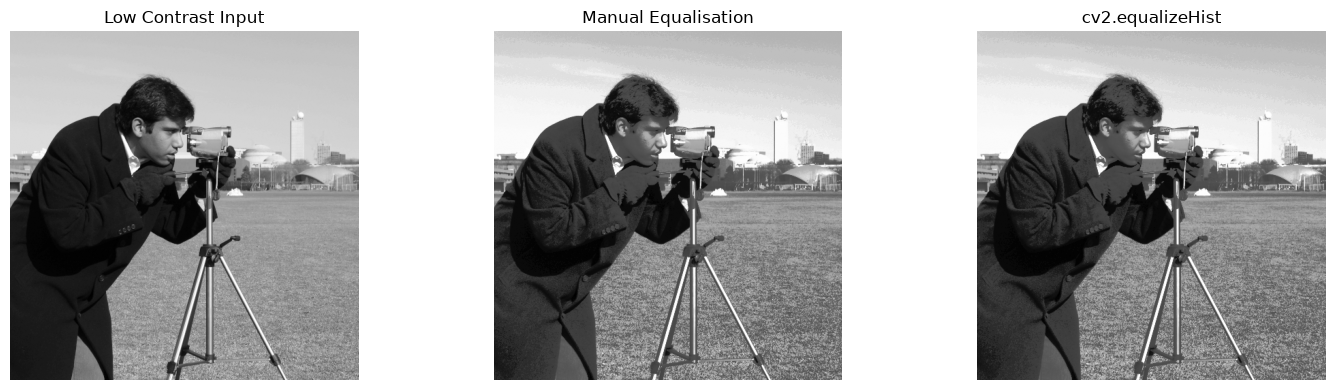

In [5]:
def histogram_equalise(image):
    """Manually perform histogram equalisation on a grayscale image."""
    hist = compute_histogram(image)
    pdf = compute_pdf(hist)
    cdf = compute_cdf(pdf)
    # Map each intensity to new value: s = round(cdf(r) * (L-1))
    L = 256
    mapping = np.round(cdf * (L - 1)).astype(np.uint8)
    equalised = mapping[image]
    return equalised

# Apply to low-contrast image (most visible effect)
eq_low = histogram_equalise(low_contrast)
# Also apply to original for completeness
eq_original = histogram_equalise(img_gray)

# Verification with OpenCV
eq_cv2 = cv2.equalizeHist(low_contrast)

# Compare manual vs OpenCV
diff = np.abs(eq_low.astype(int) - eq_cv2.astype(int))
print(f"Max difference (manual vs cv2.equalizeHist): {diff.max()}")
print(f"Mean difference: {diff.mean():.4f}")

# ---- Display: Low contrast image equalisation ----
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes[0, 0].imshow(low_contrast, cmap='gray'); axes[0, 0].set_title("Low Contrast (Original)"); axes[0, 0].axis('off')
axes[0, 1].imshow(eq_low, cmap='gray'); axes[0, 1].set_title("After Histogram Equalisation (Manual)"); axes[0, 1].axis('off')

hist_before = compute_histogram(low_contrast)
hist_after = compute_histogram(eq_low)
axes[1, 0].bar(range(256), hist_before, color='gray', width=1); axes[1, 0].set_title("Histogram Before")
axes[1, 1].bar(range(256), hist_after, color='gray', width=1); axes[1, 1].set_title("Histogram After Equalisation")
plt.tight_layout(); plt.show()

# ---- Display: Original image equalisation ----
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes[0, 0].imshow(img_gray, cmap='gray'); axes[0, 0].set_title("Original Image"); axes[0, 0].axis('off')
axes[0, 1].imshow(eq_original, cmap='gray'); axes[0, 1].set_title("After Histogram Equalisation"); axes[0, 1].axis('off')

hist_orig2 = compute_histogram(img_gray)
hist_eq2 = compute_histogram(eq_original)
axes[1, 0].bar(range(256), hist_orig2, color='gray', width=1); axes[1, 0].set_title("Histogram (Original)")
axes[1, 1].bar(range(256), hist_eq2, color='gray', width=1); axes[1, 1].set_title("Histogram (Equalised)")
plt.tight_layout(); plt.show()

# ---- Manual vs OpenCV comparison ----
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].imshow(low_contrast, cmap='gray'); axes[0].set_title("Low Contrast Input"); axes[0].axis('off')
axes[1].imshow(eq_low, cmap='gray'); axes[1].set_title("Manual Equalisation"); axes[1].axis('off')
axes[2].imshow(eq_cv2, cmap='gray'); axes[2].set_title("cv2.equalizeHist"); axes[2].axis('off')
plt.tight_layout(); plt.show()

## Conclusion

In this assignment, we explored global image enhancement through histogram-based techniques:

1. **Histogram Generation** (Task 3.1): We manually computed 256-bin histograms showing the frequency distribution of pixel intensities.
2. **Normalised Histogram / PDF** (Task 3.2): By dividing each bin by total pixels, we obtained probability density functions that sum to 1.
3. **CDF** (Task 3.3): The cumulative sum of the PDF provides a monotonically increasing mapping function.
4. **Histogram Equalisation** (Task 3.4): Using the CDF to remap intensities spreads them across the full [0, 255] range, significantly improving contrast in low-contrast images. Our manual implementation matches OpenCV's `cv2.equalizeHist` closely.

These techniques are foundational spatial-domain enhancement methods widely used in practice.